In [106]:
%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\HARSHIT\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


# Customer Churn & Revenue Intelligence

### Business Objective
Analyze customer attrition patterns to uncover key churn drivers, isolate high-risk customer segments, and quantify total revenue at risk. Build and track a predictive machine learning pipeline to identify at-risk customers early and support targeted retention strategies.

### Tech Stack
* **Languages & Querying:** Python, SQL
* **Data Manipulation & Analysis:** Pandas, NumPy
* **Data Visualization:** Matplotlib, Seaborn
* **Machine Learning & MLOps:** Scikit-learn, XGBoost, MLflow

In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [108]:
df = pd.read_excel("../data/Telco_customer_churn.xlsx")

In [109]:
df.shape

(7043, 33)

In [110]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [111]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='object')

In [112]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [113]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [114]:
df.duplicated().sum()

np.int64(0)

In [115]:
df["Churn Value"].value_counts()

Churn Value
0    5174
1    1869
Name: count, dtype: int64

In [116]:
df["Total Charges"].head(10)
df["Total Charges"] = pd.to_numeric(
    df["Total Charges"],
    errors="coerce"
)

In [117]:
df["Total Charges"].isnull().sum()

np.int64(11)

In [118]:
df[df["Total Charges"].isnull()][
    ["Tenure Months", "Monthly Charges", "Total Charges", "Churn Value"]
]

,Tenure Months,Monthly Charges,Total Charges,Churn Value
2234,0,52.55,NaN,0
2438,0,20.25,NaN,0
2568,0,80.85,NaN,0
2667,0,25.75,NaN,0
2856,0,56.05,NaN,0
4331,0,19.85,NaN,0
4687,0,25.35,NaN,0
5104,0,20.00,NaN,0
5719,0,19.70,NaN,0
6772,0,73.35,NaN,0


In [119]:
df[df["Total Charges"].isnull()]["Tenure Months"].value_counts()

Tenure Months
0    11
Name: count, dtype: int64

In [120]:
df["Total Charges"] = df["Total Charges"].fillna(0)

In [121]:
df["Total Charges"].isnull().sum()

np.int64(0)

## Churn by contract type
Are customers on month-to-month contracts more likely to leave than customers on long-term contracts?

In [122]:
churn_by_contract = df.groupby("Contract")["Churn Value"].mean() * 100
churn_by_contract

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn Value, dtype: float64

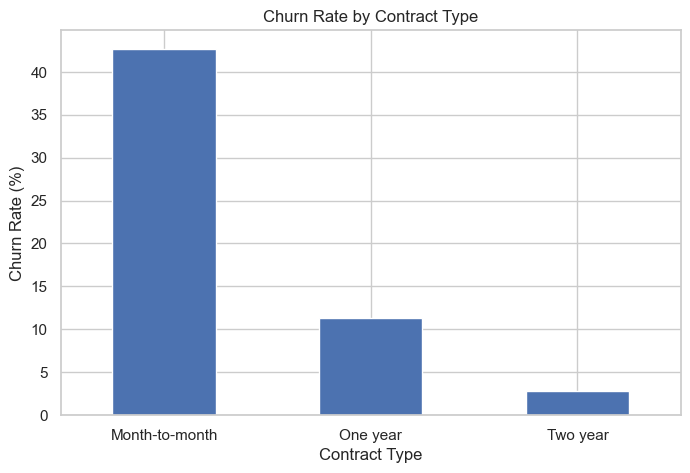

In [123]:
churn_by_contract.plot(
    kind="bar",
    figsize=(8, 5),
    title="Churn Rate by Contract Type"
)

plt.ylabel("Churn Rate (%)")
plt.xlabel("Contract Type")
plt.xticks(rotation=0)
plt.show()

### Insight 1: Contract Type and Customer Churn

Month-to-month customers have a churn rate of 42.71%,
compared to 11.27% for one-year contracts and 2.83%
for two-year contracts.

This indicates that customers with shorter contracts
are substantially more likely to churn. The company
could investigate retention offers or incentives for
month-to-month customers.

## Churn by tenure
Are new customers more likely to leave than long-term customers?

In [124]:
tenure_churn = df.groupby("Tenure Months")["Churn Value"].mean() * 100
tenure_churn

Tenure Months
0      0.000000
1     61.990212
2     51.680672
3     47.000000
4     47.159091
        ...    
68     9.000000
69     8.421053
70     9.243697
71     3.529412
72     1.657459
Name: Churn Value, Length: 73, dtype: float64

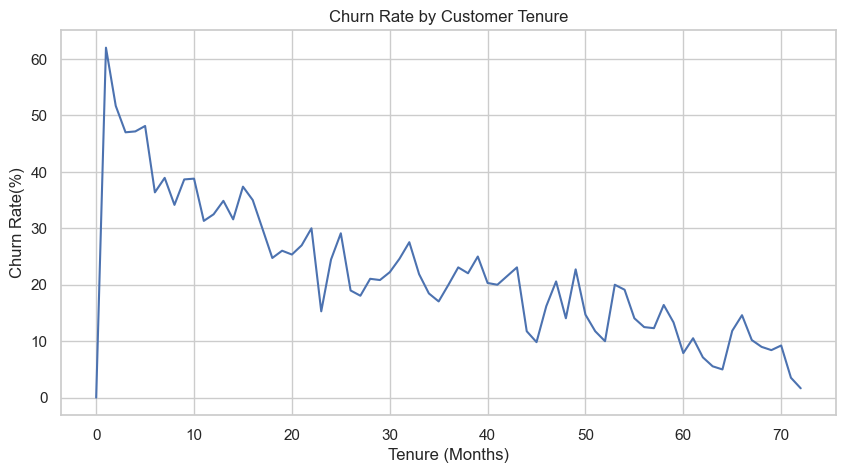

In [125]:
plt.figure(figsize=(10,5))
plt.plot(tenure_churn.index,tenure_churn.values)

plt.title("Churn Rate by Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Churn Rate(%)")
plt.show()

### Insight 2: Customer Tenure and Churn

Churn is highest during the early months of customer
tenure. Approximately 62% of customers with one month
of tenure have churned, while the churn rate at
72 months is approximately 1.66%.

This indicates that early customer retention may be
a critical area for the business. Improving onboarding
and monitoring new customers could help reduce churn.

In [126]:
df.groupby("Churn Value")["Monthly Charges"].mean()

Churn Value
0    61.265124
1    74.441332
Name: Monthly Charges, dtype: float64

### Insight 3: Monthly Charges and Churn

Customers who churned paid an average of **USD 74.44** per month, compared with **USD 61.27** for retained customers.

This suggests that customers with higher monthly charges may be more likely to churn. The company could investigate pricing, service bundles, and customer satisfaction among high-billing customers.

## Churn by payment method
whether payment method is associated with customer churn.

In [127]:
payment_churn = df.groupby("Payment Method")["Churn Value"].mean() * 100
payment_churn.sort_values(ascending=False)

Payment Method
Electronic check             45.285412
Mailed check                 19.106700
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Name: Churn Value, dtype: float64

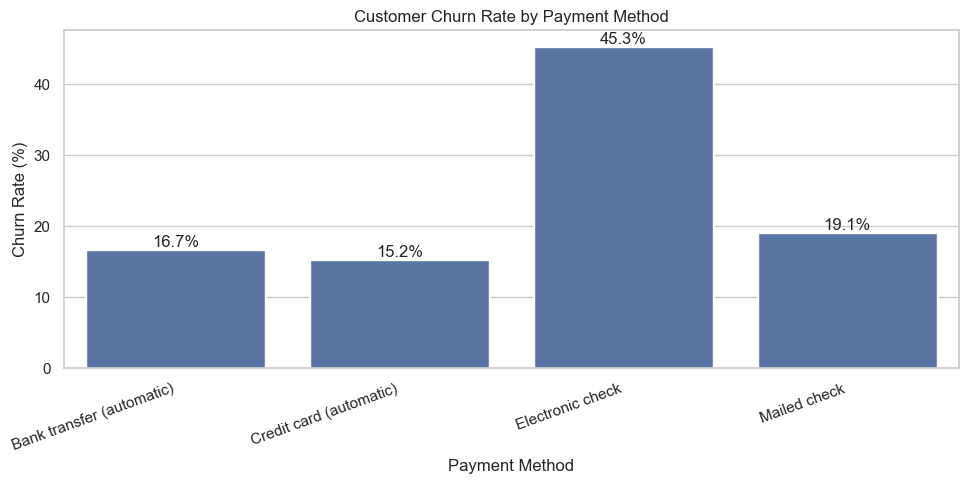

In [128]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=payment_churn.index,
    y=payment_churn.values
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

### Insight 4: Payment Method and Churn

Electronic-check customers have a churn rate of
45.29%, considerably higher than customers using
automatic bank transfer (16.71%) or credit card
payments (15.24%).

The company could investigate payment friction
and encourage convenient automatic payment options.

## Churn by internet service
whether churn differs across internet service types.

In [129]:
internet_churn = (
    df.groupby("Internet Service")["Churn Value"].mean() * 100
)
internet_churn.sort_values(ascending=False)

Internet Service
Fiber optic    41.892765
DSL            18.959108
No              7.404980
Name: Churn Value, dtype: float64

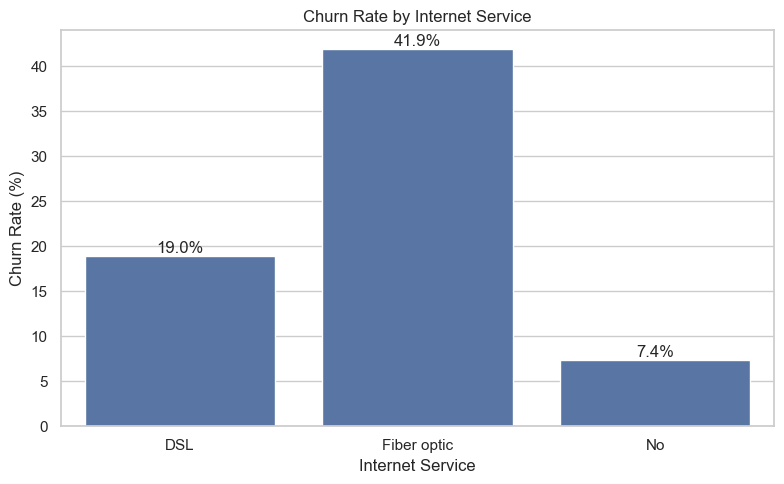

In [130]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

### Insight 5: Internet Service and Churn

Fiber optic customers have a churn rate of 41.89%,
compared with 18.96% for DSL customers and 7.40%
for customers without internet service.

This suggests that churn is concentrated among
fiber optic customers. The company should investigate
pricing, service quality, and customer satisfaction
within this segment.

### Churn by Gender.

In [131]:
gender_churn = (
    df.groupby("Gender")["Churn Value"].mean() * 100
)
gender_churn

Gender
Female    26.920872
Male      26.160338
Name: Churn Value, dtype: float64

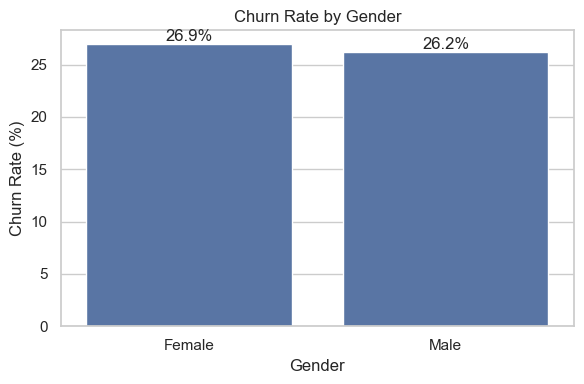

In [132]:
plt.figure(figsize=(6, 4))
ax = sns.barplot(
    x=gender_churn.index,
    y=gender_churn.values
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
plt.title("Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

### Insight 6: Gender and Churn

The churn rate among female customers is 26.92%,
while male customers have a churn rate of 26.16%.

The difference is very small, suggesting that gender
does not meaningfully distinguish churn behaviour
in this dataset.

### Churn by Senior Citizen status

In [133]:
senior_churn = (
    df.groupby("Senior Citizen")["Churn Value"].mean() * 100
)
senior_churn

Senior Citizen
No     23.606168
Yes    41.681261
Name: Churn Value, dtype: float64

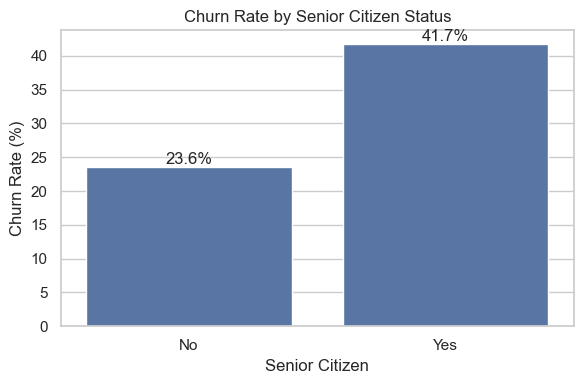

In [134]:
plt.figure(figsize=(6, 4))
ax = sns.barplot(
    x=senior_churn.index,
    y=senior_churn.values
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.title("Churn Rate by Senior Citizen Status")
plt.xlabel("Senior Citizen")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

### Insight 7: Senior Citizen Status and Churn

Senior citizen customers have a churn rate of 41.68%,
compared with 23.61% among non-senior customers.

This indicates a higher churn rate within the senior
customer segment. The company could investigate
contract preferences, pricing, and support experience
to identify potential retention opportunities.

### Churn by Partner Status

In [135]:
partner_churn = (
    df.groupby("Partner")["Churn Value"].mean() * 100
).sort_values(ascending=False)

partner_churn

Partner
No     32.957979
Yes    19.664903
Name: Churn Value, dtype: float64

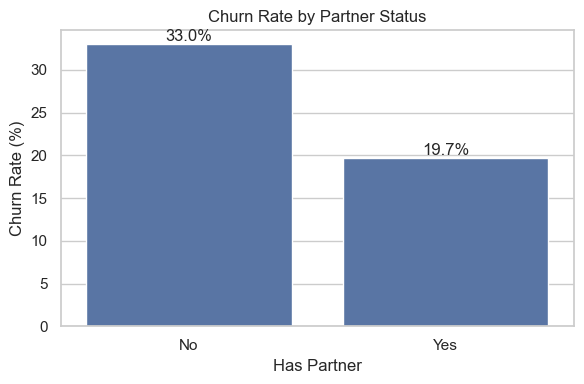

In [136]:
plt.figure(figsize=(6, 4))

ax = sns.barplot(
    x=partner_churn.index,
    y=partner_churn.values
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.title("Churn Rate by Partner Status")
plt.xlabel("Has Partner")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

In [137]:
dependent_churn = (
    df.groupby("Dependents")["Churn Value"].mean() * 100
).sort_values(ascending=False)

dependent_churn

Dependents
No     32.551699
Yes     6.515058
Name: Churn Value, dtype: float64

### Insight 9: Dependents and Churn

Customers without dependents have a churn rate of
32.55%, compared with 6.52% among customers with
dependents.

This indicates that customers without dependents
represent a substantially higher-churn segment.
The company should investigate their contract type,
tenure, and service preferences to identify possible
retention opportunities.

In [138]:
security_churn = (
    df.groupby("Online Security")["Churn Value"].mean() * 100
).sort_values(ascending=False)
security_churn

Online Security
No                     41.766724
Yes                    14.611194
No internet service     7.404980
Name: Churn Value, dtype: float64

### Insight 10: Online Security and Churn

Customers without online security have a churn rate
of 41.77%, compared with 14.61% among customers
subscribed to online security.

This suggests that customers using additional
services may have lower churn. The company could
investigate service bundles and customer engagement
as potential retention opportunities.

In [139]:
support_churn = (
    df.groupby("Tech Support")["Churn Value"].mean() * 100
).sort_values(ascending=False)
support_churn

Tech Support
No                     41.635474
Yes                    15.166341
No internet service     7.404980
Name: Churn Value, dtype: float64

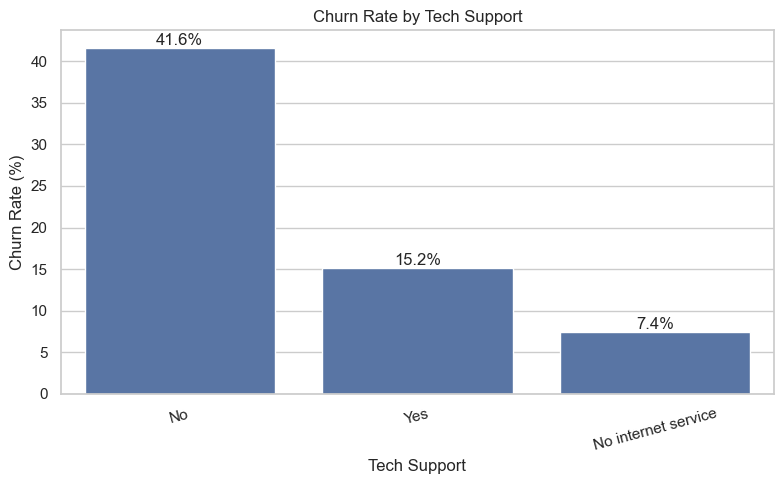

In [140]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=support_churn.index,
    y=support_churn.values
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### Insight 11: Tech Support and Churn

Customers without tech support have a churn rate of 41.64%, compared with 15.17% among customers subscribed to tech support (and 7.40% for those without internet service).

This suggests that accessible technical assistance plays a key role in customer retention. The company could investigate bundling tech support into standard plans or offering proactive troubleshooting to reduce attrition among unsupported users.

In [141]:
device_churn = (
    df.groupby("Device Protection")["Churn Value"].mean() * 100
).sort_values(ascending=False)
device_churn

Device Protection
No                     39.127625
Yes                    22.502064
No internet service     7.404980
Name: Churn Value, dtype: float64

### Insight 12: Device Protection and Churn

Customers without device protection have a churn rate of 39.13%, compared with 22.50% among customers subscribed to device protection (and 7.40% for those without internet service).

This suggests that add-on services like device protection increase customer stickiness and lower attrition. The company could investigate bundling device protection into multi-service packages or promoting it during onboarding to reduce churn among unprotected users.

In [142]:
streaming_tv_churn = (
    df.groupby("Streaming TV")["Churn Value"].mean() * 100
).sort_values(ascending=False)

streaming_tv_churn

Streaming TV
No                     33.523132
Yes                    30.070188
No internet service     7.404980
Name: Churn Value, dtype: float64

### Insight 13: Streaming TV and Churn

Customers without streaming TV have a churn rate of 33.52%, compared with 30.07% among customers with streaming TV (and 7.40% for those without internet service).

This suggests that streaming TV has only a modest difference in churn among internet users compared with add-ons like tech support or device protection. The company could investigate whether bundling streaming perks or reviewing content pricing improves retention within this segment.

In [143]:
streaming_movies_churn = (
    df.groupby("Streaming Movies")["Churn Value"].mean() * 100
).sort_values(ascending=False)

streaming_movies_churn

Streaming Movies
No                     33.680431
Yes                    29.941435
No internet service     7.404980
Name: Churn Value, dtype: float64

### Insight 14: Streaming Movies and Churn

Customers without streaming movies have a churn rate of 33.68%, compared with 29.94% among customers with streaming movies (and 7.40% for those without internet service).

This suggests that, similar to streaming TV, streaming movies has only a modest impact on churn among internet users compared with core security and support add-ons. The company could investigate whether bundling entertainment packages or offering promotional trials increases perceived value and retention.

In [144]:
paperless_churn = (
    df.groupby("Paperless Billing")["Churn Value"].mean() * 100
).sort_values(ascending=False)

paperless_churn

Paperless Billing
Yes    33.565092
No     16.330084
Name: Churn Value, dtype: float64

### Insight 15: Paperless Billing and Churn

Customers enrolled in paperless billing have a churn rate of 33.57%, compared with 16.33% among customers receiving paper bills.

This suggests that paperless billing users who often overlap with month-to-month contracts and electronic check payers are more than twice as likely to churn. The company could investigate whether digital billing users feel less engaged or are disproportionately concentrated in higher-risk, flexible payment segments.

In [145]:
phone_churn = (
    df.groupby("Phone Service")["Churn Value"].mean() * 100
).sort_values(ascending=False)

phone_churn

Phone Service
Yes    26.709637
No     24.926686
Name: Churn Value, dtype: float64

### Insight 16: Phone Service and Churn

Customers with phone service have a churn rate of 26.71%, compared with 24.93% among customers without phone service.

This suggests that having basic phone service has minimal impact on customer attrition, as churn rates remain nearly identical across both groups. The company could focus retention efforts on stronger drivers such as contract type, tenure, and internet support add-ons rather than standalone phone plans.

In [146]:
lines_churn = (
    df.groupby("Multiple Lines")["Churn Value"].mean() * 100
).sort_values(ascending=False)

lines_churn

Multiple Lines
Yes                 28.609896
No                  25.044248
No phone service    24.926686
Name: Churn Value, dtype: float64

### Insight 17: Multiple Lines and Churn

Customers with multiple phone lines have a churn rate of 28.61%, compared with 25.04% among single-line customers (and 24.93% for those without phone service).

This suggests that having multiple phone lines shows only a slight increase in churn, likely reflecting higher monthly bills rather than dissatisfaction with the service itself. The company could investigate whether multi-line customers are paying noticeably higher rates and offer family or multi-line bundle discounts to improve retention.

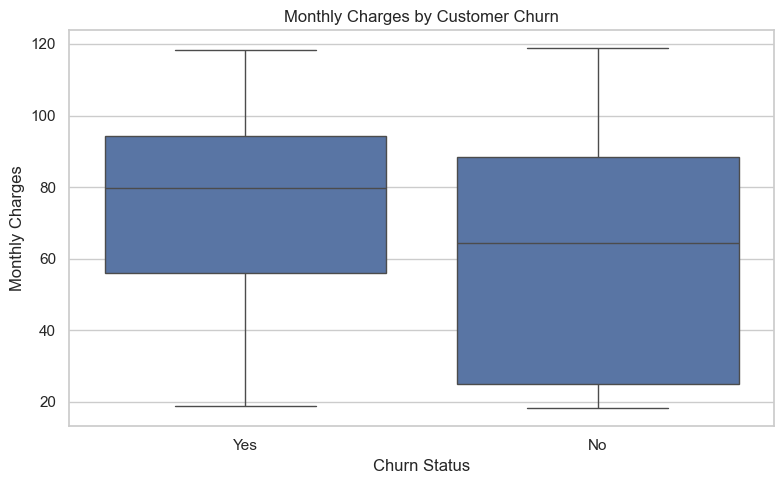

In [147]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Churn Label",
    y="Monthly Charges",
    data=df
)

plt.title("Monthly Charges by Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

In [148]:
df["Tenure Group"] = pd.cut(
    df["Tenure Months"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-60 Months",
        "61-72 Months"
    ]
)

In [149]:
tenure_group_churn = (
    df.groupby("Tenure Group", observed=False)["Churn Value"].mean() * 100
)

tenure_group_churn

Tenure Group
0-12 Months     47.438243
13-24 Months    28.710938
25-48 Months    20.388959
49-60 Months    14.423077
61-72 Months     6.609808
Name: Churn Value, dtype: float64

### Insight 18: Customer Tenure and Churn

Customers in their first year (0–12 months) have the highest churn rate at 47.44%, dropping steadily across tenure brackets to 28.71% (13–24 months), 20.39% (25–48 months), 14.42% (49–60 months), and just 6.61% for long-term customers (61–72 months).

This suggests that customer attrition is heavily concentrated in the early stages of the customer lifecycle, with retention improving dramatically once customers pass the first year. The company could strengthen onboarding programs, offer early-tenure check-ins, and incentivize annual contracts during the first 12 months to reduce early churn.

In [150]:
churned_customers = df[df["Churn Value"] == 1]
monthly_revenue_lost = churned_customers["Monthly Charges"].sum()
print("Monthly Revenue Associated with Churn:", monthly_revenue_lost)

Monthly Revenue Associated with Churn: 139130.85


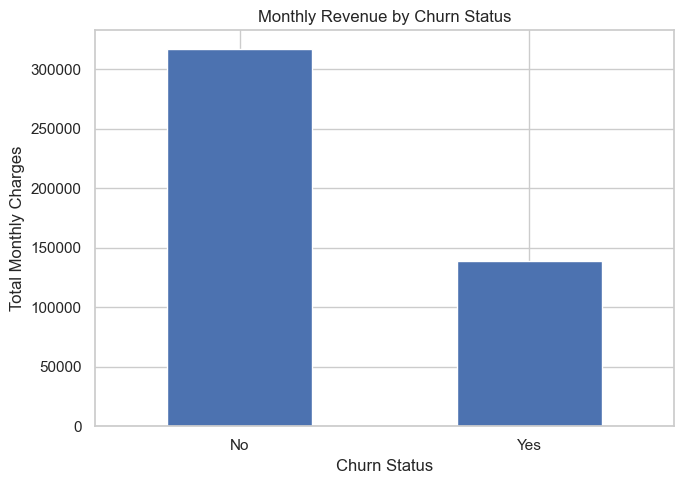

In [151]:
revenue_by_churn = df.groupby("Churn Label")[
    ["Monthly Charges", "Total Charges"]
].sum()
revenue_by_churn

revenue_by_churn["Monthly Charges"].plot(
    kind="bar",
    figsize=(7, 5),
    title="Monthly Revenue by Churn Status"
)

plt.xlabel("Churn Status")
plt.ylabel("Total Monthly Charges")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Before training, we need to prevent data leakage. Some columns, such as Churn Label, Churn Score, CLTV, and Churn Reason, could reveal information related to the outcome. We must exclude them from the initial model.

### We'll start with Logistic Regression as our baseline model.

In [152]:
model_df = df.copy()

In [153]:
model_df.shape

(7043, 34)

In [154]:
drop_cols = [
    "CustomerID",
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude",
    "Churn Label",
    "Churn Reason",
    "Churn Score",
    "CLTV",
    "Tenure Group"
]

model_df = model_df.drop(columns=drop_cols)

model_df.head()

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1


In [155]:
X = model_df.drop("Churn Value", axis=1)
y = model_df["Churn Value"]

In [156]:
X.shape, y.shape

((7043, 19), (7043,))

In [157]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Tenure Months', 'Monthly Charges', 'Total Charges']
Categorical features: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


In [158]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [159]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [160]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

In [161]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.7430801987224982
Precision: 0.5104895104895105
Recall: 0.7807486631016043
F1 Score: 0.6173361522198731
ROC-AUC: 0.8488542716164199


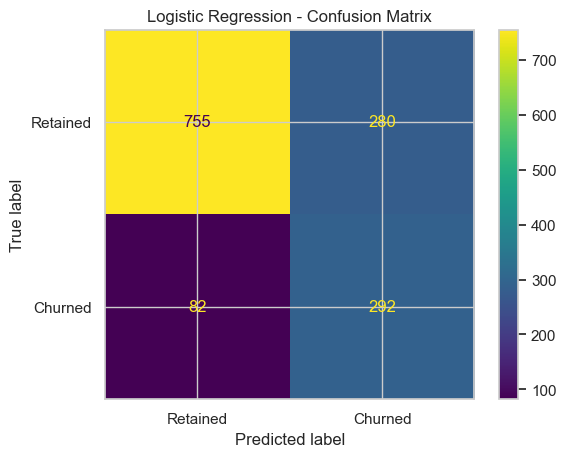

In [162]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Retained", "Churned"]
)

disp.plot()
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

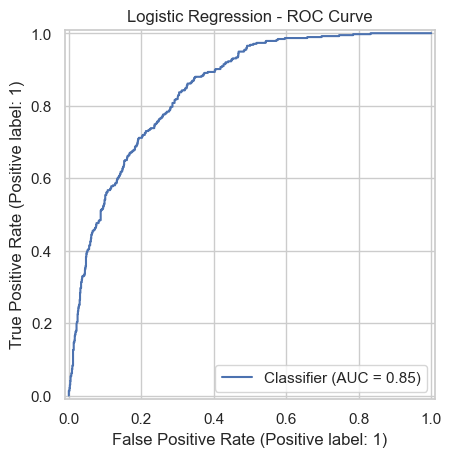

In [163]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title("Logistic Regression - ROC Curve")
plt.show()

In [164]:
baseline_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

baseline_results

{'Model': 'Logistic Regression',
 'Accuracy': 0.7430801987224982,
 'Precision': 0.5104895104895105,
 'Recall': 0.7807486631016043,
 'F1 Score': 0.6173361522198731,
 'ROC-AUC': 0.8488542716164199}

In [165]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

In [166]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["classifier"].coef_[0]
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})
feature_importance["Absolute Coefficient"] = (
    feature_importance["Coefficient"].abs()
)
feature_importance = feature_importance.sort_values(
    "Absolute Coefficient", ascending=False
)
feature_importance.head(15)

,Feature,Coefficient,Absolute Coefficient
0,num__Tenure Months,-1.209694,1.209694
10,cat__Dependents_Yes,-0.930744,0.930744
39,cat__Contract_Two year,-0.754424,0.754424
9,cat__Dependents_No,0.703389,0.703389
37,cat__Contract_Month-to-month,0.660048,0.660048
17,cat__Internet Service_Fiber optic,0.586088,0.586088
16,cat__Internet Service_DSL,-0.558362,0.558362
1,num__Monthly Charges,-0.551369,0.551369
2,num__Total Charges,0.515836,0.515836
40,cat__Paperless Billing_No,-0.273652,0.273652


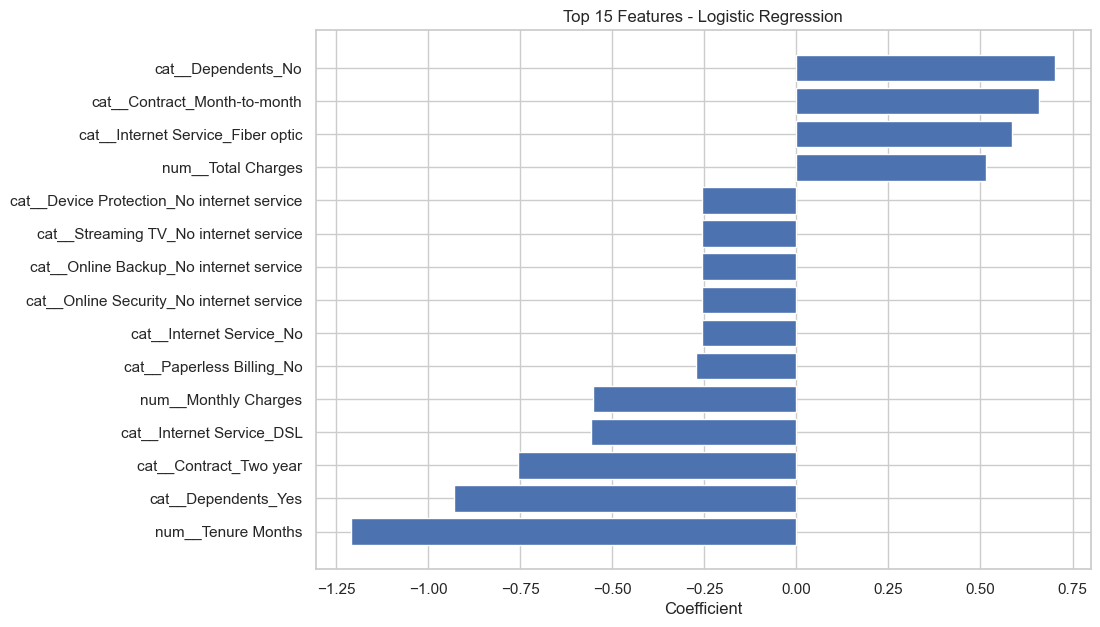

In [167]:
top_features = feature_importance.head(15).sort_values(
    "Coefficient"
)
plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)
plt.title("Top 15 Features - Logistic Regression")
plt.xlabel("Coefficient")
plt.show()

In [168]:
from sklearn.ensemble import RandomForestClassifier
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['Gender','Senior Citizen','Partner',...,'Payment Method', 'Monthly Charges','Total Charges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``rema

In [169]:
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

In [170]:
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))
print("ROC-AUC:", roc_auc_score(y_test, rf_prob))

Accuracy: 0.7750177430801988
Precision: 0.5664335664335665
Recall: 0.6497326203208557
F1 Score: 0.6052303860523038
ROC-AUC: 0.8336175049730037


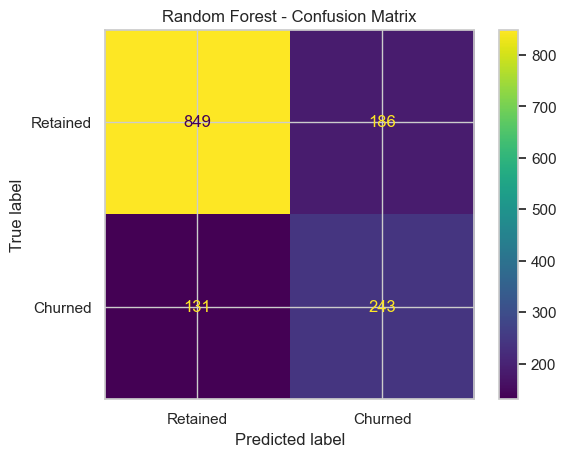

In [171]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=["Retained", "Churned"]
)
plt.title("Random Forest - Confusion Matrix")
plt.show()

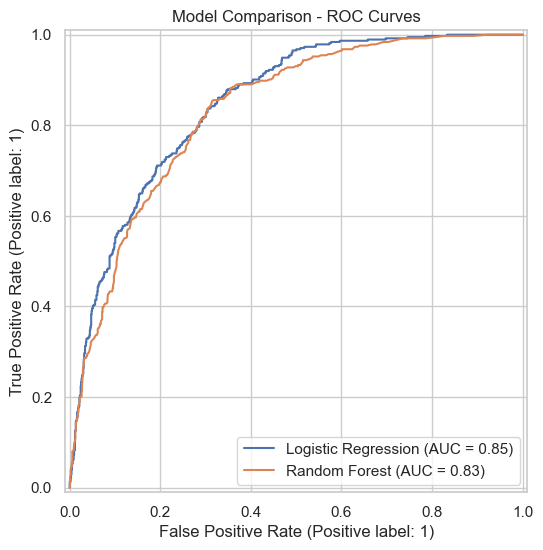

In [172]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test, y_prob,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test, rf_prob,
    name="Random Forest",
    ax=ax
)

plt.title("Model Comparison - ROC Curves")
plt.show()

In [173]:
comparison = pd.DataFrame([
    baseline_results,
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred),
        "Recall": recall_score(y_test, rf_pred),
        "F1 Score": f1_score(y_test, rf_pred),
        "ROC-AUC": roc_auc_score(y_test, rf_prob)
    }
])
comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.743080,0.510490,0.780749,0.617336,0.848854
1,Random Forest,0.775018,0.566434,0.649733,0.605230,0.833618


In [174]:
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    cross_validate,
    cross_val_predict,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss
)

from sklearn.calibration import (
    CalibratedClassifierCV,
    calibration_curve
)

In [175]:
def create_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric_features),
            (
                "cat",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            )
        ]
    )

In [176]:
log_model = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [177]:
rf_model = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=1
    ))
])

In [178]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\HARSHIT\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [179]:
from xgboost import XGBClassifier
xgb_model = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

In [180]:
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=2,
    random_state=42
)
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "brier": "neg_brier_score"
}

In [181]:
models = {
    "Logistic Regression": log_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

cv_results = {}

for name, estimator in models.items():
    print("Evaluating:", name)

    cv_results[name] = cross_validate(
        estimator,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

Evaluating: Logistic Regression
Evaluating: Random Forest
Evaluating: XGBoost


In [182]:
results = []
for name, scores in cv_results.items():
    results.append({
        "Model": name,
        "ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std(),
        "PR-AUC Mean": scores["test_pr_auc"].mean(),
        "PR-AUC Std": scores["test_pr_auc"].std(),
        "Precision Mean": scores["test_precision"].mean(),
        "Recall Mean": scores["test_recall"].mean(),
        "F1 Mean": scores["test_f1"].mean(),
        "Brier Score": -scores["test_brier"].mean()
    })

cv_summary = pd.DataFrame(results)

cv_summary.sort_values(
    "PR-AUC Mean",
    ascending=False
)

,Model,ROC-AUC Mean,ROC-AUC Std,PR-AUC Mean,PR-AUC Std,Precision Mean,Recall Mean,F1 Mean,Brier Score
2,XGBoost,0.859350,0.007395,0.681994,0.015363,0.655535,0.552713,0.599497,0.130783
0,Logistic Regression,0.857481,0.006559,0.673754,0.013773,0.665702,0.579729,0.619511,0.130870
1,Random Forest,0.836961,0.006228,0.632091,0.015756,0.647645,0.508844,0.569397,0.140531


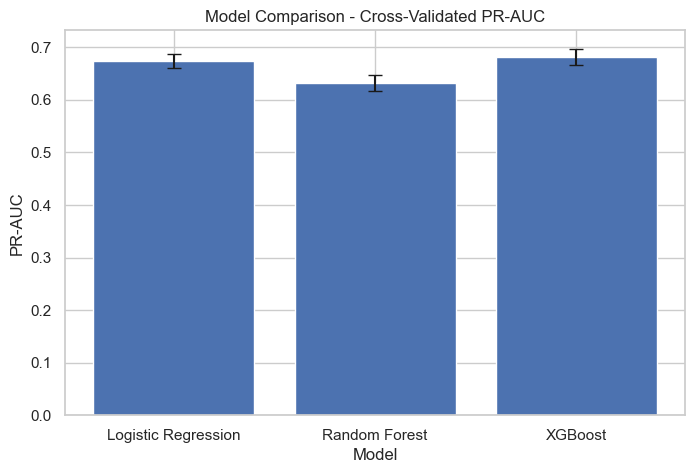

In [183]:
plt.figure(figsize=(8, 5))
plt.bar(
    cv_summary["Model"],
    cv_summary["PR-AUC Mean"],
    yerr=cv_summary["PR-AUC Std"],
    capsize=5
)
plt.title("Model Comparison - Cross-Validated PR-AUC")
plt.ylabel("PR-AUC")
plt.xlabel("Model")
plt.show()

In [184]:
selected_name = "Logistic Regression"  # change after comparison
selected_model = models[selected_name]
calibrated_model = CalibratedClassifierCV(
    estimator=selected_model,
    method="sigmoid",
    cv=5
)

In [185]:
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
oof_prob = cross_val_predict(
    calibrated_model,
    X,
    y,
    cv=outer_cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [186]:
print("ROC-AUC:", roc_auc_score(y, oof_prob))
print("PR-AUC:", average_precision_score(y, oof_prob))
print("Brier Score:", brier_score_loss(y, oof_prob))

ROC-AUC: 0.8577758839884073
PR-AUC: 0.6731648097493045
Brier Score: 0.1307573641472177


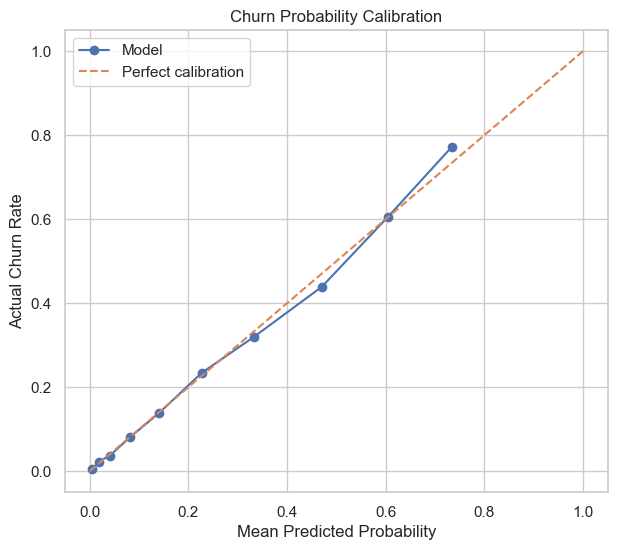

In [187]:
prob_true, prob_pred = calibration_curve(
    y,
    oof_prob,
    n_bins=10,
    strategy="quantile"
)
plt.figure(figsize=(7, 6))
plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Model"
)
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)
plt.title("Churn Probability Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Actual Churn Rate")
plt.legend()
plt.show()

In [188]:
offer_cost = 500 / 85 
offer_success_rate = 0.20
expected_remaining_months = 12
contribution_margin_rate = 0.40

In [189]:
monthly_charges = X["Monthly Charges"].to_numpy()
expected_future_contribution = (
    monthly_charges* expected_remaining_months* contribution_margin_rate
)
expected_benefit = (
    oof_prob * offer_success_rate * expected_future_contribution
)
net_offer_value = expected_benefit - offer_cost

In [190]:
targeting_results = pd.DataFrame({
    "CustomerID": df.loc[X.index, "CustomerID"].values,
    "Churn Probability": oof_prob,
    "Monthly Charges": monthly_charges,
    "Expected Future Contribution": expected_future_contribution,
    "Expected Benefit": expected_benefit,
    "Net Offer Value": net_offer_value
})
targeting_results = targeting_results.sort_values(
    "Net Offer Value",
    ascending=False
)
targeting_results.head(20)

,CustomerID,Churn Probability,Monthly Charges,Expected Future Contribution,Expected Benefit,Net Offer Value
1827,1400-MMYXY,0.840617,105.90,508.32,85.460499,79.578147
584,7216-EWTRS,0.863248,100.80,483.84,83.534804,77.652451
1681,8884-ADFVN,0.823469,101.95,489.36,80.594540,74.712187
1566,6496-SLWHQ,0.798231,105.00,504.00,80.461681,74.579328
974,6688-UZPWD,0.820463,102.00,489.60,80.339774,74.457421
1044,4587-VVTOX,0.790957,105.30,505.44,79.956278,74.073925
886,5178-LMXOP,0.868424,95.10,456.48,79.283660,73.401307
852,3902-FOIGH,0.813213,101.35,486.48,79.122380,73.240027
684,6861-XWTWQ,0.829764,99.25,476.40,79.059911,73.177558
1707,5419-JPRRN,0.808651,101.45,486.96,78.756133,72.873780


In [191]:
profitable_customers = targeting_results[
    targeting_results["Net Offer Value"] > 0
]
print("Customers worth targeting:", len(profitable_customers))

Customers worth targeting: 4071


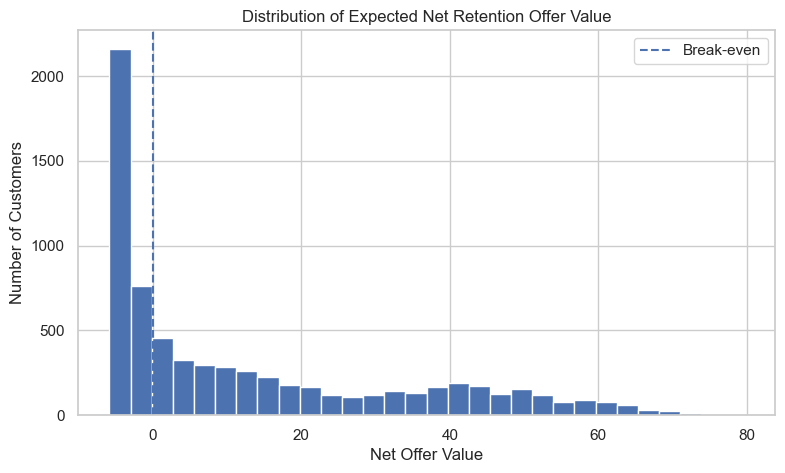

In [192]:
plt.figure(figsize=(9, 5))
plt.hist(
    targeting_results["Net Offer Value"],
    bins=30
)
plt.axvline(
    0,
    linestyle="--",
    label="Break-even"
)
plt.title("Distribution of Expected Net Retention Offer Value")
plt.xlabel("Net Offer Value")
plt.ylabel("Number of Customers")
plt.legend()
plt.show()

In [193]:
total_expected_value = profitable_customers["Net Offer Value"].sum()
print(
    "Total Expected Net Offer Value:",
    round(total_expected_value, 2)
)

Total Expected Net Offer Value: 103728.56


In [194]:
active_mask = df["Churn Value"] == 0
active_df = df.loc[active_mask].copy()
active_prob = oof_prob[active_mask.to_numpy()]

In [195]:
active_df["Churn Probability"] = active_prob
active_df["Monthly Revenue at Risk"] = (
    active_prob * active_df["Monthly Charges"]
)
print(
    "Total Monthly Revenue at Risk:",
    active_df["Monthly Revenue at Risk"].sum()
)

Total Monthly Revenue at Risk: 65876.73799043191


In [196]:
active_df["Expected Benefit"] = (
    active_prob * offer_success_rate  * active_df["Monthly Charges"]
    * expected_remaining_months
    * contribution_margin_rate
)

active_df["Net Offer Value"] = (
    active_df["Expected Benefit"] - offer_cost
)

In [197]:
pd.crosstab(
    [df["Contract"], df["Internet Service"]],
    df["Payment Method"],
    values=df["Churn Value"],
    aggfunc="mean"
).round(3)

Payment Method                   Bank transfer (automatic)  \
Contract       Internet Service                              
Month-to-month DSL                                   0.198   
               Fiber optic                           0.456   
               No                                    0.200   
One year       DSL                                   0.076   
               Fiber optic                           0.146   
               No                                    0.045   
Two year       DSL                                   0.013   
               Fiber optic                           0.093   
               No                                    0.006   

Payment Method                   Credit card (automatic)  Electronic check  \
Contract       Internet Service                                              
Month-to-month DSL                                 0.270             0.405   
               Fiber optic                         0.416             0.604   
               No                                  0.092             0.188   
One year       DSL                                 0.099             0.095   
               Fiber optic                         0.153             0.260   
               No                                  0.013             0.057   
Two year       DSL                                 0.021             0.069   
               Fiber optic                         0.039             0.098   
               No                                  0.011             0.000   

Payment Method                   Mailed check  
Contract       Internet Service                
Month-to-month DSL                      0.308  
               Fiber optic              0.507  
               No                       0.206  
One year       DSL                      0.102  
               Fiber optic              0.194  
               No                       0.012  
Two year       DSL                      0.000  
               Fiber optic              0.048  
               No                       0.008

In [198]:
from scipy.stats import chi2_contingency
import numpy as np

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table)[0]
    n = table.sum().sum()
    r, k = table.shape

    return np.sqrt(chi2 / (n * min(r - 1, k - 1)))

for col in ["Contract", "Internet Service", "Payment Method"]:
    table = pd.crosstab(df[col], df["Churn Value"])
    chi2, p, _, _ = chi2_contingency(table)

    print(
        col,
        "p-value:", round(p, 5),
        "Cramér's V:", round(cramers_v(df[col], df["Churn Value"]), 3)
    )

Contract p-value: 0.0 Cramér's V: 0.41
Internet Service p-value: 0.0 Cramér's V: 0.322
Payment Method p-value: 0.0 Cramér's V: 0.303


In [199]:
for internet in df["Internet Service"].unique():
    subset = df[df["Internet Service"] == internet]

    print("\nInternet Service:", internet)

    print(
        pd.crosstab(
            subset["Contract"],
            subset["Churn Value"],
            normalize="index"
        ).round(3)
    )


Internet Service: DSL
Churn Value         0      1
Contract                    
Month-to-month  0.678  0.322
One year        0.907  0.093
Two year        0.981  0.019

Internet Service: Fiber optic
Churn Value         0      1
Contract                    
Month-to-month  0.454  0.546
One year        0.807  0.193
Two year        0.928  0.072

Internet Service: No
Churn Value         0      1
Contract                    
Month-to-month  0.811  0.189
One year        0.975  0.025
Two year        0.992  0.008


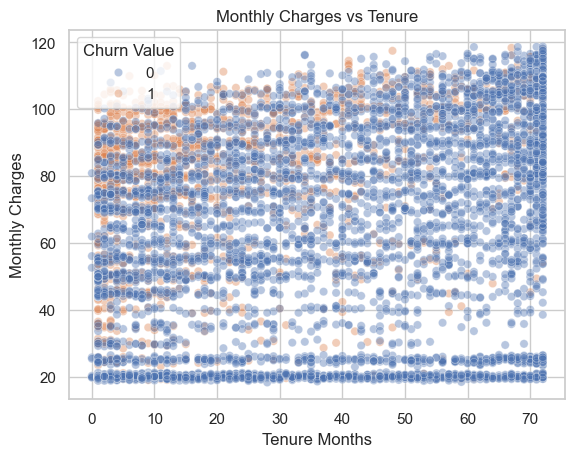

In [200]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.scatterplot(
    data=df,
    x="Tenure Months",
    y="Monthly Charges",
    hue="Churn Value",
    alpha=0.4
)

plt.title("Monthly Charges vs Tenure")
plt.show()

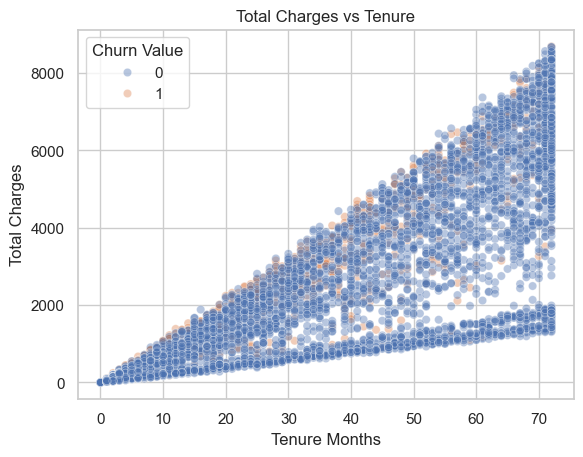

In [201]:
sns.scatterplot(
    data=df,
    x="Tenure Months",
    y="Total Charges",
    hue="Churn Value",
    alpha=0.4
)
plt.title("Total Charges vs Tenure")
plt.show()

In [202]:
for col in ["Partner", "Dependents"]:
    print("\n", col)
    print(
        df.groupby(col)["Churn Value"]
        .mean()
        .mul(100)
        .round(2)
    )


 Partner
Partner
No     32.96
Yes    19.66
Name: Churn Value, dtype: float64

 Dependents
Dependents
No     32.55
Yes     6.52
Name: Churn Value, dtype: float64


In [203]:
from sklearn.model_selection import train_test_split

drop_cols = [
    "CustomerID", "Count", "Country", "State", "City",
    "Zip Code", "Lat Long", "Latitude", "Longitude",
    "Churn Label", "Churn Reason", "Churn Score", "CLTV",
    "Tenure Group"
]

X = model_df.drop(columns=drop_cols + ["Churn Value"], errors="ignore")
y = model_df["Churn Value"]

In [204]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


In [205]:
def add_features(data):
    data = data.copy()

    service_cols = [
        "Phone Service", "Multiple Lines",
        "Online Security", "Online Backup",
        "Device Protection", "Tech Support",
        "Streaming TV", "Streaming Movies"
    ]

    data["Service Count"] = (
        data[service_cols] == "Yes"
    ).sum(axis=1)

    data["Average Monthly Spend"] = (
        data["Total Charges"] /
        data["Tenure Months"].replace(0, np.nan)
    )

    data["Tenure Group"] = pd.cut(
        data["Tenure Months"],
        bins=[-1, 12, 24, 48, 60, 72],
        labels=[
            "0-12", "13-24", "25-48",
            "49-60", "61-72"
        ]
    )

    return data

In [206]:
X_train_features = add_features(X_train)
X_test_features = add_features(X_test)

In [207]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

def create_preprocessor(data):
    numeric_cols = data.select_dtypes(
        include=["int64", "float64"]
    ).columns

    categorical_cols = data.select_dtypes(
        include=["object", "category"]
    ).columns

    numeric_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ])

In [208]:
def evaluate_features(data, y_train):
    pipeline = Pipeline([
        ("preprocessor", create_preprocessor(data)),
        ("model", LogisticRegression(max_iter=1000))
    ])

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        pipeline,
        data,
        y_train,
        cv=cv,
        scoring="average_precision"
    )

    return scores.mean(), scores.std()

In [209]:
baseline_mean, baseline_std = evaluate_features(
    X_train, y_train
)

print("Baseline PR-AUC:", round(baseline_mean, 4))

Baseline PR-AUC: 0.68


In [210]:
candidate_features = [
    "Service Count",
    "Average Monthly Spend",
    "Tenure Group"
]

for feature in candidate_features:
    test_data = X_train.copy()
    test_data[feature] = X_train_features[feature]

    mean_score, std_score = evaluate_features(
        test_data, y_train
    )

    print(
        feature,
        "PR-AUC:", round(mean_score, 4),
        "Std:", round(std_score, 4)
    )

Service Count PR-AUC: 0.6801 Std: 0.0204
Average Monthly Spend PR-AUC: 0.6784 Std: 0.0197
Tenure Group PR-AUC: 0.6855 Std: 0.0137
